In [1]:
import batman
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from kepler_utils import *
import batman_utils

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.02                                   #planet radius [stellar radii]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142.9e-6                               #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K] (not used by the batman models, only for the PlanetParams object)

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

offset = 0.                                 # hotspot offset delta (atmospheric winds redistributing heat east of substellar point, in degrees)

t = np.linspace(-period/4, period*3/4, 10000)

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

### Transit

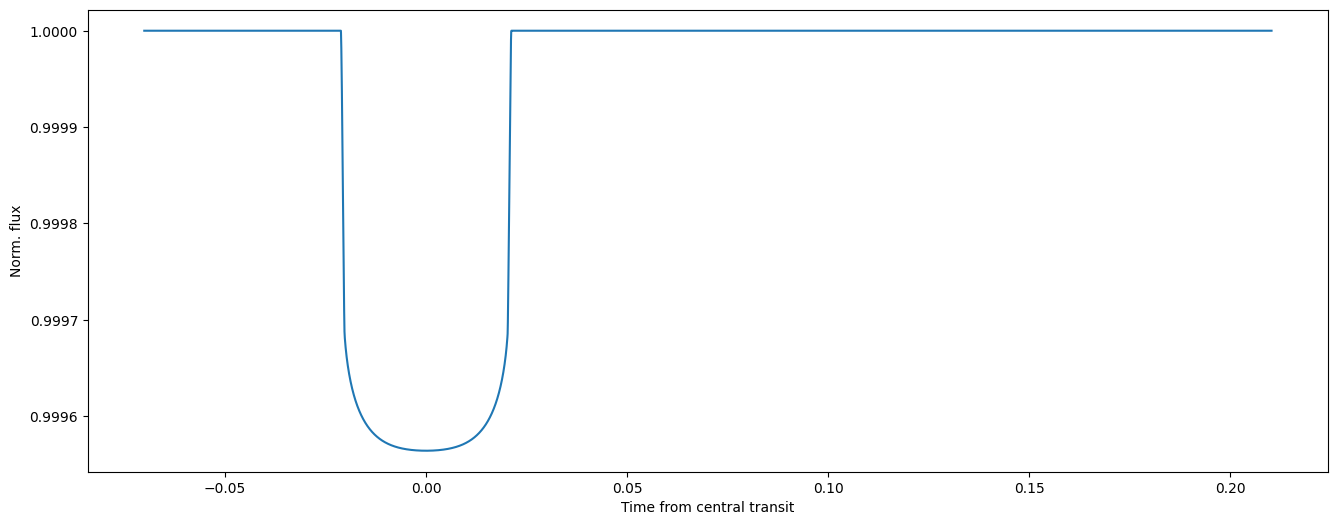

In [4]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_transit(K2_141b, t, u=u))
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Occultation

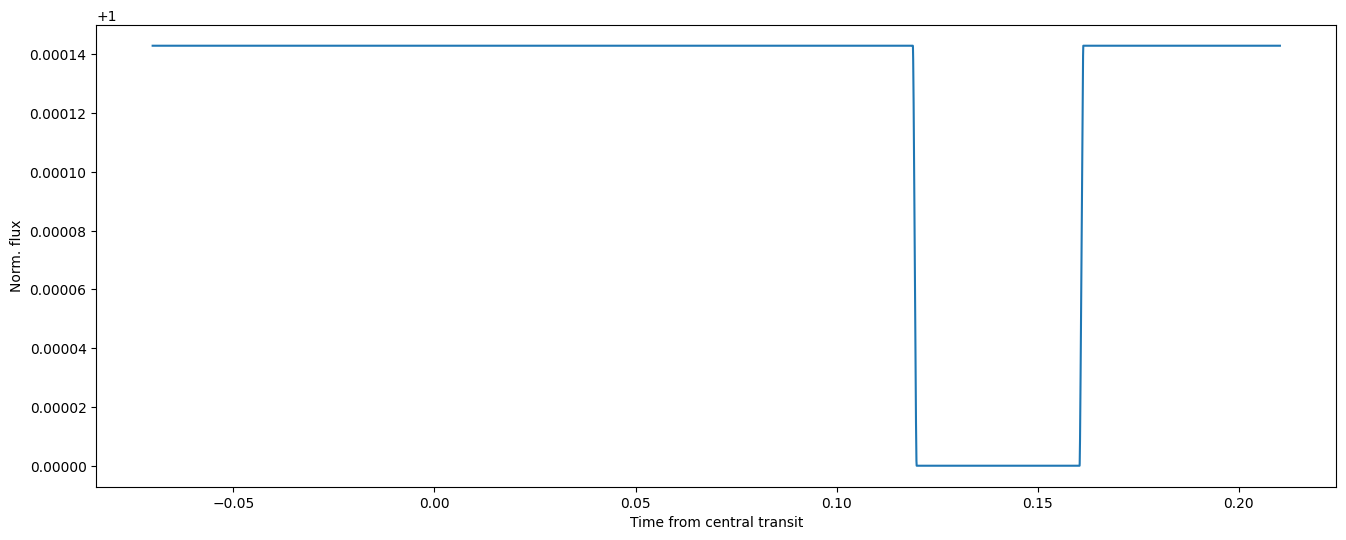

In [5]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_occultation(K2_141b, fp, t))
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Occultation + Planetary Phases

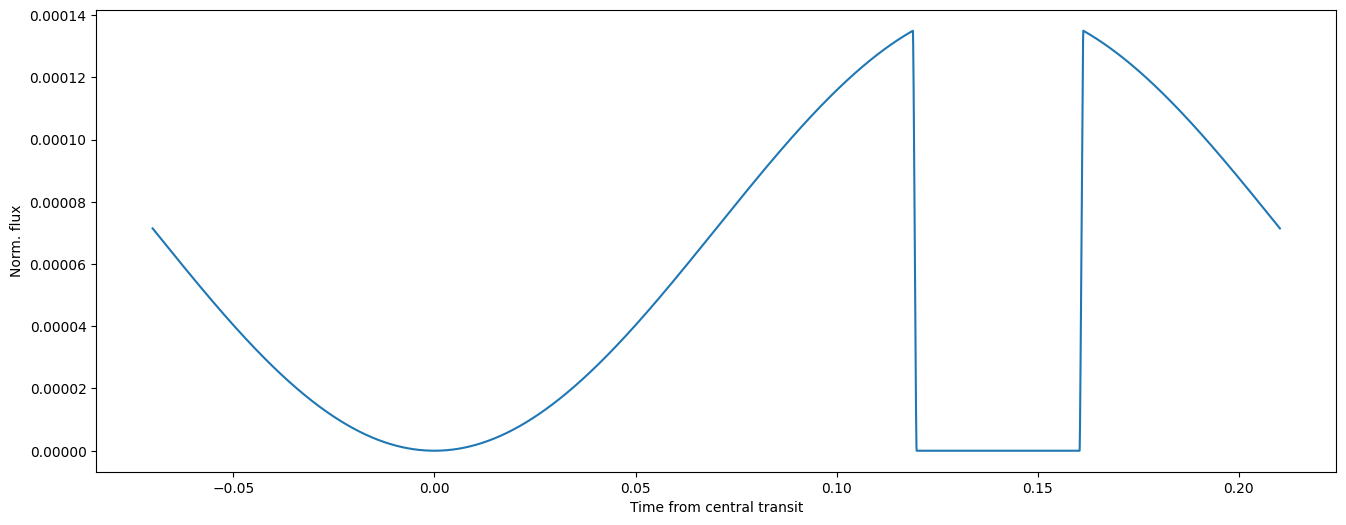

In [6]:
Amp=1. # Phase Curve Amplitude ( A = 1 - F_p,min / F_p,max = (T_night / T_day)^4 )
phase_mod = 1 + Amp/2 * (np.cos(2*np.pi * (t/period - 0.5) + np.radians(offset)) - 1)
plt.figure(figsize=(16, 6))
plt.plot(t, (batman_utils.flux_occultation(K2_141b, fp, t)-1)*phase_mod)
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Transit + Occultation + Planetary Phases

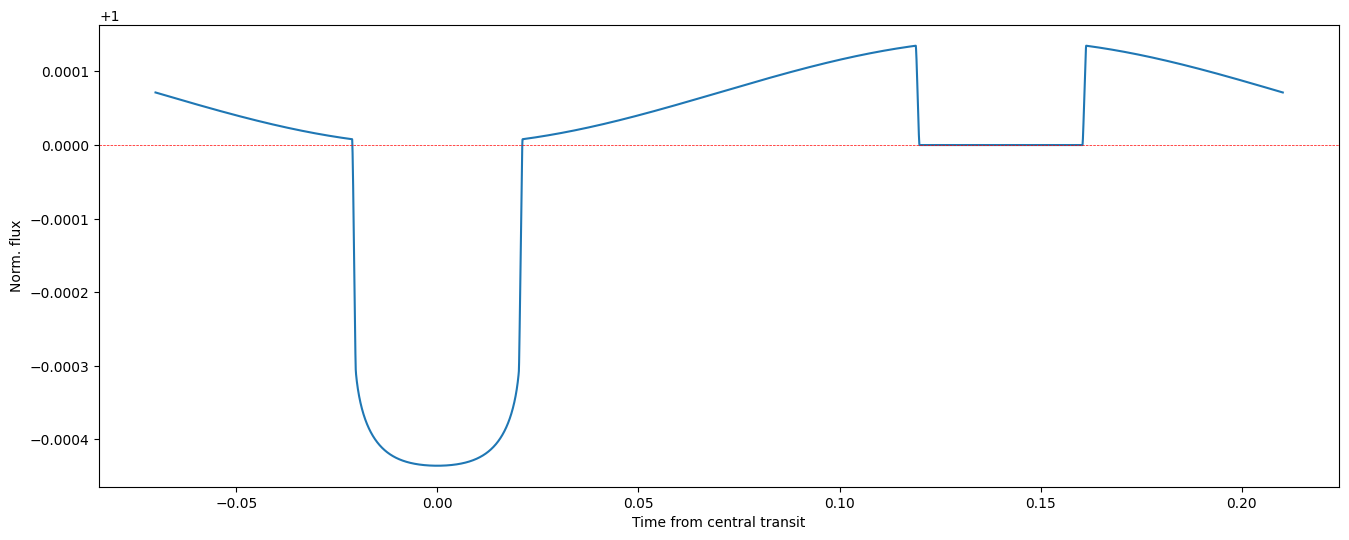

In [7]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_transit(K2_141b, t, u=u)+(batman_utils.flux_occultation(K2_141b, fp, t)-1)*phase_mod)
plt.axhline(1, color='r', linestyle='--', linewidth=0.5)
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

## Complete observable PhaseCurve

In [8]:
t, flux = batman_utils.Cosine_PhaseCurve(K2_141b, fp, u=u)

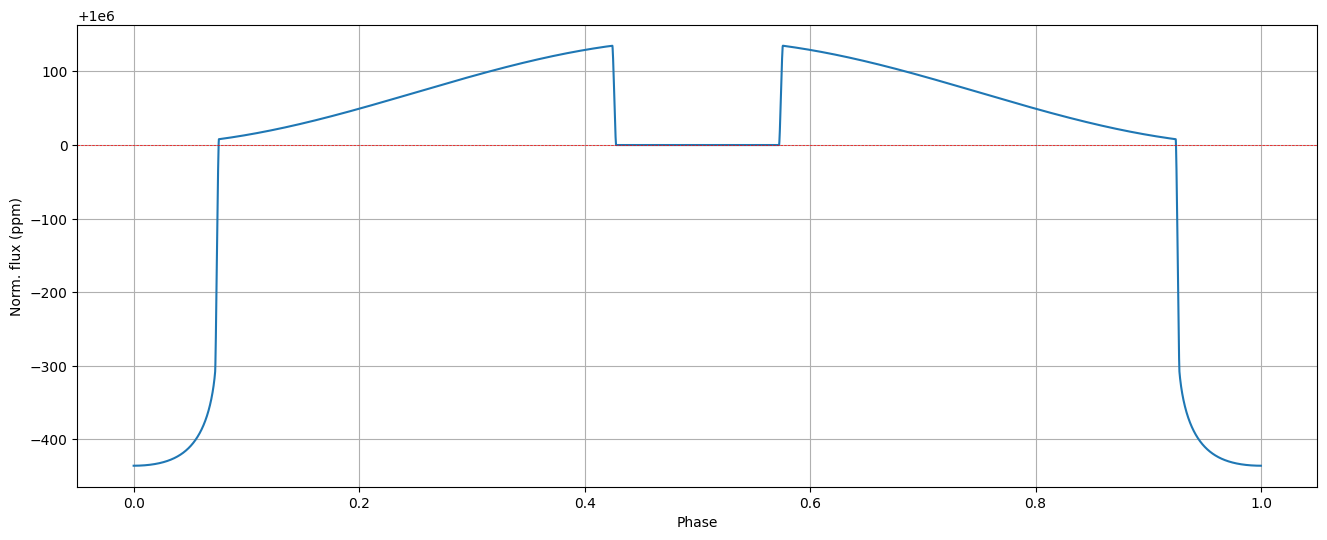

In [9]:
plt.figure(figsize=(16, 6))
plt.plot(t/period, flux*1e6)
plt.axhline(1e6, color='r', linestyle='--', linewidth=0.5)
plt.xlabel("Phase")
plt.ylabel("Norm. flux (ppm)")
# plt.minorticks_on()
# plt.grid(which='minor')
plt.grid(which='major')
plt.show()

## Effect of quadratic limb darkening

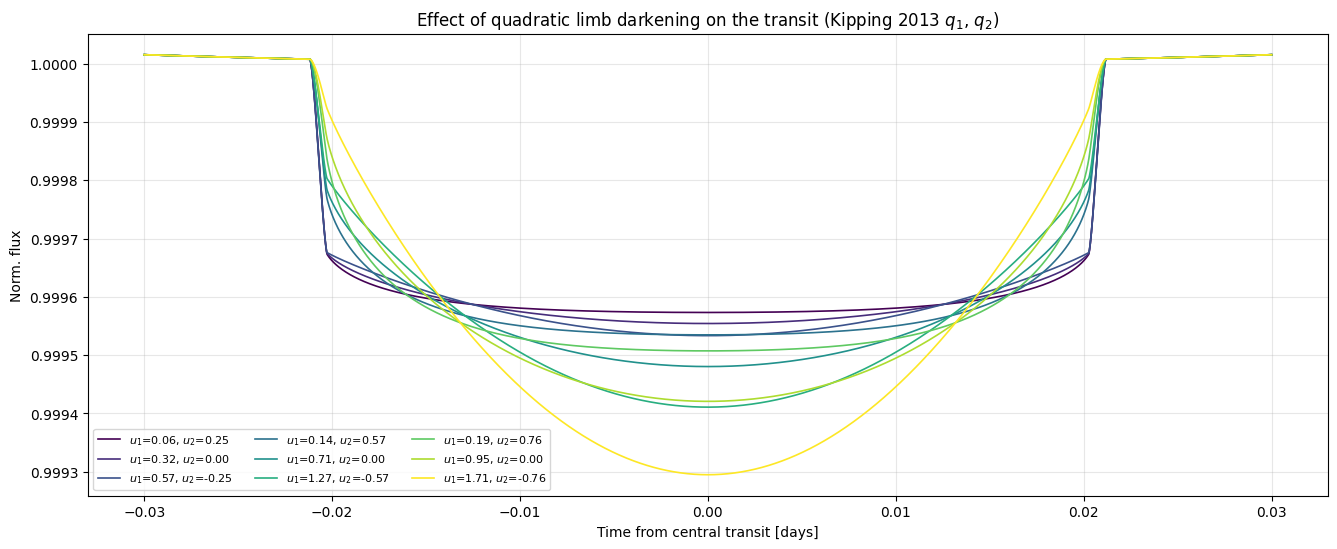

In [10]:
# Effect of quadratic limb darkening on the transit, sampled via the Kipping (2013) (q1, q2) parametrization
q_vals = np.linspace(0.1, 0.9, 3)                        # equally spaced q1, q2
qsets  = [(q1, q2) for q1 in q_vals for q2 in q_vals]    # equally spaced sets of (q1, q2)
t_ld   = np.linspace(-0.03, 0.03, 4000)                  # transit window [days]

cmap = plt.cm.viridis
plt.figure(figsize=(16, 6))
for k, (q1, q2) in enumerate(qsets):
    sq1 = np.sqrt(q1)
    u1, u2 = 2*sq1*q2, sq1*(1 - 2*q2)                    # Kipping (2013) inverse
    _, flux = batman_utils.Cosine_PhaseCurve(K2_141b, fp, t=t_ld, u=[u1, u2])
    plt.plot(t_ld, flux, linewidth=1.2, color=cmap(k/(len(qsets)-1)),
             label=f"$u_1$={u1:.2f}, $u_2$={u2:.2f}")
plt.xlabel("Time from central transit [days]")
plt.ylabel("Norm. flux")
plt.title("Effect of quadratic limb darkening on the transit (Kipping 2013 $q_1$, $q_2$)")
plt.legend(fontsize=8, ncol=3)
plt.grid(alpha=.3)
plt.show()